In [ ]:
import io                                                          # io: para leer el archivo subido desde la memoria
import numpy as np                                                 # numpy: para trabajar con números y valores vacíos (nan)
import pandas as pd                                                # pandas: para manejar tablas de datos (DataFrames)
import matplotlib.pyplot as plt                                    # matplotlib: para dibujar gráficos, como el árbol
from google.colab import files                                     # files: para mostrar el botón de carga en Colab
from sklearn.model_selection import train_test_split               # para dividir los datos en entrenamiento y prueba
from sklearn.tree import DecisionTreeClassifier, plot_tree         # el árbol de decisión y la función para dibujarlo
from sklearn.metrics import accuracy_score, confusion_matrix       # para medir qué tan bien predice el modelo

# Cargar el Excel
archivo = files.upload()                                           # muestra el botón "Elegir archivos" y espera el Excel
contenido = io.BytesIO(archivo[list(archivo.keys())[0]])           # guarda en memoria el archivo que se subió
clientes = pd.read_excel(contenido, sheet_name="clientes")         # lee la hoja "clientes" (datos para entrenar)
nuevos = pd.read_excel(contenido, sheet_name="clientes_nuevos")    # lee la hoja "clientes_nuevos" (datos a predecir)
display(clientes.head())                                           # muestra las primeras 5 filas para revisar

# Explorar
print(clientes.dtypes)                                             # muestra el tipo de dato de cada columna
print(clientes.isna().sum())                                       # cuenta cuántos valores vacíos hay por columna
print("Duplicados:", clientes.duplicated().sum())                  # cuenta cuántas filas están repetidas
print("cancelo:", clientes["cancelo"].unique())                    # muestra las formas distintas en que se escribió "cancelo"
print("plan:", clientes["plan"].unique())                          # muestra las formas distintas en que se escribió "plan"
display(clientes.describe())                                       # muestra mínimos, máximos y promedios de las columnas numéricas

# Limpiar
datos = clientes.drop(columns=["encuesta_salida"])                 # elimina la columna con información del futuro

datos["cancelo"] = datos["cancelo"].str.strip().str.lower().replace({"si": "Sí", "sí": "Sí", "no": "No"})  # quita espacios, pasa a minúsculas y unifica en Sí / No
datos["plan"] = datos["plan"].str.strip().str.lower().replace({    # quita espacios y pasa a minúsculas el plan
    "basico": "Básico", "básico": "Básico",                        # todas las variantes de básico → "Básico"
    "estandar": "Estándar", "estándar": "Estándar",                # todas las variantes de estándar → "Estándar"
    "premium": "Premium"})                                         # todas las variantes de premium → "Premium"

datos = datos.drop_duplicates().dropna(subset=["cancelo"])         # elimina filas repetidas y filas sin respuesta en "cancelo"

datos["gasto_mensual"] = pd.to_numeric(                            # convierte gasto_mensual a número...
    datos["gasto_mensual"].astype(str).str.replace("₡", "").str.replace(",", "").str.strip())  # ...después de quitar el ₡, la coma y los espacios

datos.loc[(datos["edad"] < 18) | (datos["edad"] > 100), "edad"] = np.nan   # edades imposibles → se marcan como vacías
datos.loc[datos["quejas"] < 0, "quejas"] = np.nan                          # quejas negativas → se marcan como vacías
datos.loc[datos["meses_activo"] > 60, "meses_activo"] = np.nan             # más de 60 meses (imposible) → se marca como vacío

for col in ["edad", "quejas", "meses_activo"]:                     # recorre las tres columnas numéricas con vacíos
    datos[col] = datos[col].fillna(datos[col].median())            # rellena los vacíos con la mediana de esa columna

print("Filas limpias:", len(datos))                                # muestra cuántas filas quedaron después de limpiar

# X e Y
planes = {"Básico": 1, "Estándar": 2, "Premium": 3}                # diccionario para convertir el plan en número
datos["plan_num"] = datos["plan"].map(planes)                      # crea la columna plan_num (1, 2 o 3)
datos["cancelo_num"] = datos["cancelo"].map({"No": 0, "Sí": 1})    # convierte la respuesta a número (0 = No, 1 = Sí)

columnas_X = ["edad", "meses_activo", "quejas", "plan_num", "gasto_mensual"]  # las pistas que usará el modelo
X = datos[columnas_X]                                              # X: variables independientes (las pistas)
y = datos["cancelo_num"]                                           # y: variable dependiente (lo que queremos predecir)

# Entrenar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # 80% entrenamiento, 20% prueba

arbol = DecisionTreeClassifier(max_depth=3, random_state=42)       # crea el árbol con máximo 3 niveles de preguntas
arbol.fit(X_train, y_train)                                        # entrena el árbol con los datos de entrenamiento

plt.figure(figsize=(18, 8))                                        # prepara un espacio grande para el dibujo
plot_tree(arbol, feature_names=columnas_X, class_names=["No cancela", "Cancela"], filled=True)  # dibuja el árbol con colores
plt.show()                                                         # muestra el dibujo

# Evaluar
pred = arbol.predict(X_test)                                       # el árbol predice los clientes de prueba
print(f"Exactitud: {accuracy_score(y_test, pred):.2%}")            # porcentaje de predicciones correctas
display(pd.DataFrame(confusion_matrix(y_test, pred),               # tabla de aciertos y errores (matriz de confusión)
                     index=["Real No", "Real Sí"], columns=["Pred No", "Pred Sí"]))  # nombres de filas y columnas

# Predecir clientes nuevos
nuevos["plan_num"] = nuevos["plan"].map(planes)                    # convierte el plan de los clientes nuevos a número
prob = arbol.predict_proba(nuevos[columnas_X])[:, 1]               # probabilidad de que cada cliente nuevo cancele
nuevos["prob_cancelar"] = (prob * 100).round(1)                    # la pasa a porcentaje con un decimal
nuevos["prediccion"] = np.where(prob >= 0.5, "Cancela", "No cancela")  # 50% o más → Cancela; menos → No cancela
display(nuevos[["id_cliente", "meses_activo", "quejas", "plan", "prob_cancelar", "prediccion"]])  # muestra el resultado final
rango = pd.DataFrame({"horas_aire": np.linspace(0, 300, 100)})  # 100 valores de horas entre 0 y 300 para dibujar la línea
plt.scatter(hogares["horas_aire"], hogares["recibo"], label="Hogares")                     # puntos reales
plt.plot(rango["horas_aire"], modelo.predict(rango), color="red", linewidth=3, label="Modelo")  # línea roja del modelo
plt.xlabel("Horas de aire acondicionado al mes")     # título del eje horizontal
plt.ylabel("Monto del recibo")                       # título del eje vertical
plt.legend()                                         # muestra la leyenda (qué es cada cosa)
plt.show()                                           # muestra el gráfico
planes = pd.DataFrame({"horas_aire": [250, 150, 50]})                         # tabla con tres escenarios de uso
planes["recibo_estimado"] = modelo.predict(planes[["horas_aire"]]).round(2)   # recibo que predice el modelo para cada escenario
print(planes)                                                                 # muestra la tabla de escenarios
ahorro = planes["recibo_estimado"].iloc[0] - planes["recibo_estimado"].iloc[1]  # diferencia entre 250 horas (fila 0) y 150 horas (fila 1)
print(f"Bajar de 250 a 150 horas ahorraría unos {ahorro:.2f} al mes")          # imprime el ahorro estimado

   horas_aire  recibo
0        15.0   11.22
1        87.0   18.42
2       216.0   42.57
3         6.0   20.76
4        62.0   22.32


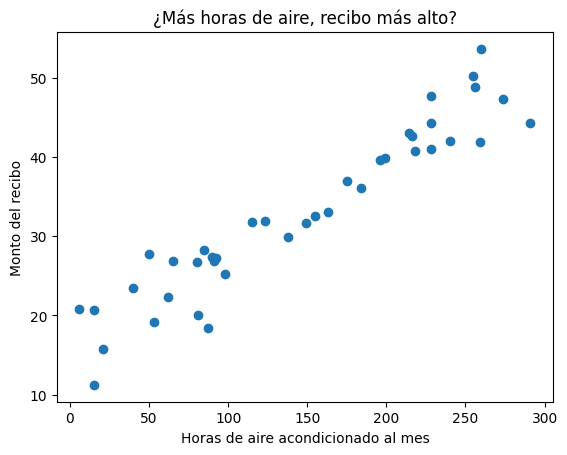

Cargo fijo estimado: 15.75
Costo por hora de aire: 0.119
Regla aprendida: recibo = 15.75 + 0.119 × horas de aire


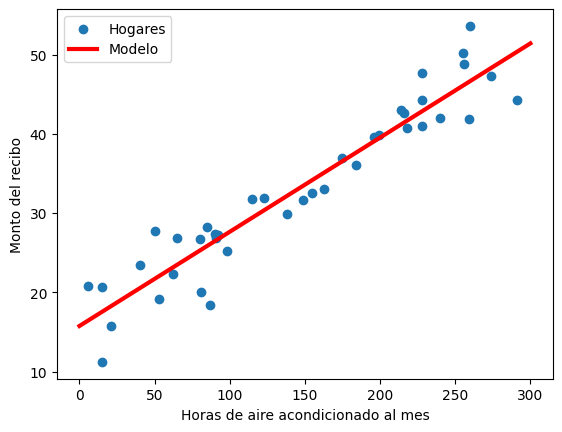

   horas_aire  recibo_estimado
0         250            45.46
1         150            33.58
2          50            21.70
Bajar de 250 a 150 horas ahorraría unos 11.88 al mes


In [8]:
#Recibo de electricidad Regresion y clasificacion
import numpy as np                                   # numpy: cálculos numéricos y números aleatorios
import pandas as pd                                  # pandas: manejar datos en forma de tabla
import matplotlib.pyplot as plt                      # matplotlib: dibujar gráficos
from sklearn.linear_model import LinearRegression    # el modelo de regresión lineal de scikit-learn

np.random.seed(21)                                   # fija el azar para que todos obtengan los mismos datos
horas_aire = np.random.uniform(0, 300, 40)           # 40 valores al azar entre 0 y 300 horas de aire al mes
ruido = np.random.normal(0, 4, 40)                   # pequeñas diferencias por otros aparatos (nevera, luces...)
recibo = 15 + 0.12 * horas_aire + ruido              # regla "real": 15 fijo + 0.12 por hora + el ruido
hogares = pd.DataFrame({"horas_aire": horas_aire.round(0),   # crea la tabla: columna de horas redondeadas
                        "recibo": recibo.round(2)})          # y columna del recibo con 2 decimales
print(hogares.head())                                # muestra las primeras 5 filas de la tabla

plt.scatter(hogares["horas_aire"], hogares["recibo"])  # grafico de puntos
plt.xlabel("Horas de aire acondicionado al mes")        # titulo del eje horizontal
plt.ylabel("Monto del recibo")                          # titulo del eje vertical
plt.title("¿Más horas de aire, recibo más alto?")       # titulo del grafico
plt.show()                                              # muestra el grafico en pantalla

#Separar entradas y objetivo
X =hogares[["horas_aire"]] # entradas doble
y =hogares["recibo"]       # objetivo
#Entrenar
modelo = LinearRegression()                          # crea un modelo de regresión lineal vacío
modelo.fit(X, y)                                     # entrena: busca el punto de partida y la pendiente

#Leer lo que apredio
cargo_fijo = modelo.intercept_                       # punto de partida: recibo estimado con 0 horas de aire
costo_hora = modelo.coef_[0]                         # pendiente: cuánto sube el recibo por cada hora de aire
print(f"Cargo fijo estimado: {cargo_fijo:.2f}")      # imprime el cargo fijo con 2 decimales
print(f"Costo por hora de aire: {costo_hora:.3f}")   # imprime el costo por hora con 3 decimales
print(f"Regla aprendida: recibo = {cargo_fijo:.2f} + {costo_hora:.3f} × horas de aire") # imprime la fórmula completa

#Dibujar la linea del modelo.
rango = pd.DataFrame({"horas_aire": np.linspace(0, 300, 100)})  # 100 valores de horas entre 0 y 300 para dibujar la línea
plt.scatter(hogares["horas_aire"], hogares["recibo"], label="Hogares")                     # puntos reales
plt.plot(rango["horas_aire"], modelo.predict(rango), color="red", linewidth=3, label="Modelo")  # línea roja del modelo
plt.xlabel("Horas de aire acondicionado al mes")     # título del eje horizontal
plt.ylabel("Monto del recibo")                       # título del eje vertical
plt.legend()                                         # muestra la leyenda (qué es cada cosa)
plt.show()                                           # muestra el gráfico

#Comparar escenarios de ahorro
planes = pd.DataFrame({"horas_aire": [250, 150, 50]})                         # tabla con tres escenarios de uso
planes["recibo_estimado"] = modelo.predict(planes[["horas_aire"]]).round(2)   # recibo que predice el modelo para cada escenario
print(planes)                                                                 # muestra la tabla de escenarios
ahorro = planes["recibo_estimado"].iloc[0] - planes["recibo_estimado"].iloc[1]  # diferencia entre 250 horas (fila 0) y 150 horas (fila 1)
print(f"Bajar de 250 a 150 horas ahorraría unos {ahorro:.2f} al mes")          # imprime el ahorro estimado

In [11]:
import numpy as np                                   # numpy: cálculos numéricos y números aleatorios
import pandas as pd                                  # pandas: manejar datos en forma de tabla
import matplotlib.pyplot as plt                      # matplotlib: dibujar gráficos
from sklearn.linear_model import LinearRegression    # el modelo de regresión lineal de scikit-learn
from sklearn.model_selection import train_test_split # función para dividir en entrenamiento y prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score # métricas: error promedio, error cuadrático y R²


#Crea 250 autos usados
np.random.seed(8)                                # fija el azar para que todos obtengan los mismos datos
n = 250                                          # cantidad de autos a crear
antiguedad = np.random.randint(1, 16, n)          # años del auto, entre 1 y 15
kilometraje = np.random.randint(5, 250, n)       # miles de kilómetros recorridos, entre 5 y 249
motor = np.random.choice([1.2, 1.6, 2.0, 2.5], n) # tamaño del motor en litros, elegido de 4 opciones
precio = (18000 - 700 * antiguedad - 25 * kilometraje + 3000 * motor # regla "real" del precio (valores ilustrativos)
          + np.random.normal(0, 1200, n))        # más ruido: estado, color, accesorios...
autos = pd.DataFrame({"antiguedad": antiguedad, "kilometraje_miles": kilometraje,  # crea la tabla con las entradas
                      "motor_litros": motor, "precio": precio.round(0)})         # y el precio redondeado

print(autos.head())                       # muestra las primeras 5 filas
print(autos.describe().round(1))          # resumen de cada columna: promedio, mínimo, máximo...


#3 Separar y dividir
X=autos[["antiguedad", "kilometraje_miles", "motor_litros"]] #entrtadas de info
y=autos["precio"] #objetivo
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
    ) #dividir en entrenamiento y prueba

print("Entrenamiento:", len(X_train), "autos | Prueba:", len(X_test), "autos")  # cuántos autos quedaron en cada grupo

#4Entrenar
modelo = LinearRegression()       # crea un modelo de regresión lineal vacío
modelo.fit(X_train, y_train)      # entrena: busca un coeficiente para cada característica

#5 Interpretar cada cohefiente
tabla = pd.DataFrame({"variable":X.columns, "coeficiente": modelo.coef_.round(1) })
print("Punto de partida", round(modelo.intercept_, 0))
print(tabla)

#6 Evaluar
y_pred = modelo.predict(X_test)                      # precios estimados para los autos de prueba
mae = mean_absolute_error(y_test, y_pred)            # error promedio en dólares
rmse = np.sqrt(mean_squared_error(y_test, y_pred))   # error que castiga más los fallos grandes
r2 = r2_score(y_test, y_pred)                        # porcentaje de variación explicado (máximo 1)
print(f"Error promedio (MAE): {mae:,.0f} dólares")   # imprime el error promedio
print(f"Error con castigo (RMSE): {rmse:,.0f} dólares")  # imprime el error con castigo
print(f"Porcentaje explicado (R²): {r2:.3f}")        # imprime el R² con 3 decimales

#7
anuncio = pd.DataFrame({"antiguedad": [6], "kilometraje_miles": [90], "motor_litros": [1.6]})  # auto del anuncio
estimado = modelo.predict(anuncio)[0]                # precio que estima el modelo
pedido = 19000                                       # precio que pide el vendedor
print(f"Precio estimado por el modelo: {estimado:,.0f} dólares")      # imprime el precio estimado
print(f"Diferencia con lo que piden: {pedido - estimado:,.0f} dólares")  # imprime cuánto más (o menos) piden

   antiguedad  kilometraje_miles  motor_litros   precio
0           4                 81           1.2  13878.0
1           5                 90           1.2  16700.0
2           2                166           2.0  18756.0
3          10                 70           2.0  14429.0
4           6                203           2.0  16102.0
       antiguedad  kilometraje_miles  motor_litros   precio
count       250.0              250.0         250.0    250.0
mean          8.2              128.3           1.9  14784.9
std           4.2               71.5           0.5   3901.6
min           1.0                6.0           1.2   4152.0
25%           4.0               70.0           1.6  11715.8
50%           8.0              129.0           2.0  14753.0
75%          12.0              193.5           2.5  17614.0
max          15.0              248.0           2.5  23755.0
Entrenamiento: 200 autos | Prueba: 50 autos
Error promedio (MAE): 1,001 dólares
Error con castigo (RMSE): 1,269 dólares
Porc